# 04 - Avaliação e Inferência

## Objetivo

Este notebook tem como objetivo comparar, de forma justa e reproduzível, os dois modelos de recomendação criados no projeto:

- **KNN item-based**: `KNNWithMeans`, similaridade do cosseno e `k = 5`, conforme o notebook `02_knn.ipynb`.
- **SVD/Funk SVD**: modelo `SVD` com os hiperparâmetros selecionados no notebook `03_svd.ipynb`.

A comparação usa o mesmo dataset, a mesma escala de ranking e a mesma divisão treino/teste para os dois modelos. Além das métricas de erro, o notebook também compara métricas de classificação, métricas Top-K e exemplos de inferência para o mesmo usuário.

## 1. Setup

Nesta etapa são importadas as bibliotecas necessárias para carregar os dados, treinar os modelos, calcular as métricas e gerar gráficos comparativos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict

from surprise import Dataset, Reader, KNNWithMeans, SVD, accuracy
from surprise.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

## 2. Carregamento do dataset tratado

A base utilizada neste notebook é o dataset tratado nas etapas anteriores do projeto. Ela contém as colunas `user_id`, `item_id` e `ranking`, que representam respectivamente o usuário, o espetáculo e a intensidade da interação.

Esse mesmo dataset foi utilizado nos notebooks de KNN e SVD, garantindo que a comparação entre os modelos seja feita a partir da mesma estrutura de dados.

In [2]:
possible_paths = [
    Path("../dataset/dataset.csv"),
    Path("src/dataset/dataset.csv"),
    Path("dataset/dataset.csv")
]

dataset_path = next((path for path in possible_paths if path.exists()), None)

if dataset_path is None:
    raise FileNotFoundError("Arquivo dataset.csv não encontrado nos caminhos esperados.")

df = pd.read_csv(dataset_path)

print("Dataset carregado de:", dataset_path)
df.head()

Dataset carregado de: ..\dataset\dataset.csv


,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,1,120.0,Show Stand-Up
1,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,1,50.0,Show Musical
2,3,A NOVIÇA REBELDE,1,225.0,Espetáculo Musical
3,4,MUSICAL HAIRSPRAY,1,350.0,Espetáculo Musical
4,5,A NOVIÇA REBELDE,1,125.0,Espetáculo Musical


In [3]:
print("Dimensão do dataset:", df.shape)
print("Usuários únicos:", df["user_id"].nunique())
print("Itens únicos:", df["item_id"].nunique())
print("Ranking mínimo:", df["ranking"].min())
print("Ranking máximo:", df["ranking"].max())

Dimensão do dataset: (109916, 5)
Usuários únicos: 68499
Itens únicos: 449
Ranking mínimo: 1
Ranking máximo: 5


## 3. Preparação dos dados para comparação

Para garantir uma comparação justa, KNN e SVD devem ser avaliados com o mesmo dataset, a mesma escala de ranking e a mesma divisão entre treino e teste.

Como os modelos foram implementados com a biblioteca `scikit-surprise`, os dados foram convertidos para o formato esperado pela biblioteca: usuário, item e rating.

A escala utilizada foi de 1 a 5, coerente com o ranking construído na etapa de preparação dos dados. A divisão adotada foi de 80% para treino e 20% para teste, com `random_state=42` para garantir reprodutibilidade.

In [4]:
reader = Reader(rating_scale=(1, 5))

data = Dataset.load_from_df(
    df[["user_id", "item_id", "ranking"]],
    reader
)

trainset, testset = train_test_split(
    data,
    test_size=0.2,
    random_state=42
)

print("Dados preparados para comparação.")
print("Tamanho do conjunto de teste:", len(testset))

Dados preparados para comparação.
Tamanho do conjunto de teste: 21984


## 4. Métricas de Avaliação

A avaliação dos modelos foi feita a partir de três perspectivas: regressão, classificação binária e qualidade da lista Top-K.

As métricas de regressão medem a diferença entre o ranking real e o ranking previsto pelo modelo. As métricas de classificação transformam o problema em uma decisão binária: se uma interação é relevante ou não relevante. Já as métricas Top-K avaliam se os itens relevantes aparecem nas primeiras posições da lista recomendada.

Essa avaliação combinada é importante porque a base da Aventura utiliza feedback implícito. Ou seja, o ranking não representa uma nota explícita de satisfação, mas sim intensidade de interação.

### Métricas utilizadas

| Métrica | Tipo de avaliação | O que mede | Como interpretar |
|---|---|---|---|
| RMSE | Regressão | Raiz do erro quadrático médio entre o ranking real e o previsto | Quanto menor, melhor. Penaliza erros grandes com mais intensidade |
| MAE | Regressão | Erro absoluto médio entre o ranking real e o previsto | Quanto menor, melhor. Indica o erro médio em unidades de ranking |
| Acurácia | Classificação | Proporção total de classificações corretas | Quanto maior, melhor, mas pode ser enganosa em bases desbalanceadas |
| Precisão | Classificação | Entre os itens previstos como relevantes, quantos eram realmente relevantes | Quanto maior, menor a quantidade de falsos positivos |
| Recall | Classificação | Entre os itens realmente relevantes, quantos foram recuperados pelo modelo | Quanto maior, menor a quantidade de falsos negativos |
| F1-score | Classificação | Média harmônica entre precisão e recall | Quanto maior, melhor o equilíbrio entre precisão e recall |

No contexto deste notebook, a classificação binária considera `ranking >= 2` como interação relevante e `ranking < 2` como interação não relevante.

### 4.1. Métricas de regressão

**RMSE (Root Mean Squared Error)**

$$
\text{RMSE} = \sqrt{\frac{1}{|\mathcal{T}|} \sum_{(u,i) \in \mathcal{T}} (r_{ui} - \hat{r}_{ui})^2}
$$

O RMSE mede a raiz do erro quadrático médio entre o ranking real e o ranking previsto. Como ele eleva os erros ao quadrado, penaliza erros maiores com mais intensidade.

**MAE (Mean Absolute Error)**

$$
\text{MAE} = \frac{1}{|\mathcal{T}|} \sum_{(u,i) \in \mathcal{T}} |r_{ui} - \hat{r}_{ui}|
$$

O MAE mede o erro absoluto médio entre o ranking real e o ranking previsto. Ele é mais interpretável, pois indica o quanto, em média, a previsão se afasta do valor real.

Quanto menores os valores de RMSE e MAE, melhor o desempenho do modelo na tarefa de predição de ranking.

### 4.2. Métricas de classificação

Para calcular métricas de classificação, o problema foi convertido em uma tarefa binária.

Foi definido o seguinte limiar:

- `ranking >= 2`: interação relevante;
- `ranking < 2`: interação não relevante.

Esse threshold foi escolhido porque o ranking é um feedback implícito construído a partir da quantidade de interações. Assim, valores maiores ou iguais a 2 indicam que o usuário teve mais de uma interação distinta com determinado espetáculo, representando um sinal mais forte de interesse.

Com essa transformação, foram calculadas:

- **Acurácia**: proporção geral de classificações corretas;
- **Precisão**: entre os itens previstos como relevantes, quantos eram realmente relevantes;
- **Recall**: entre os itens realmente relevantes, quantos foram identificados pelo modelo;
- **F1-score**: média harmônica entre precisão e recall.

## 5. Treinamento dos modelos para comparação

Embora os modelos KNN e SVD já tenham sido desenvolvidos em notebooks específicos, nesta etapa eles são treinados novamente usando exatamente a mesma divisão de treino e teste. Assim, a diferença observada nas métricas vem do comportamento dos algoritmos, e não de divisões diferentes da base.

### 5.1. Modelo KNN

O modelo KNN utilizado na comparação foi o `KNNWithMeans`, configurado como item-based por meio do parâmetro `user_based=False`.

A métrica de similaridade utilizada foi o cosseno, e o valor de `k` foi definido como 5, seguindo a configuração do notebook específico de KNN.

In [5]:
sim_options = {
    "name": "cosine",
    "user_based": False
}

modelo_knn = KNNWithMeans(
    k=5,
    sim_options=sim_options,
    verbose=False
)

modelo_knn.fit(trainset)

predictions_knn = modelo_knn.test(testset)

rmse_knn = accuracy.rmse(predictions_knn, verbose=False)
mae_knn = accuracy.mae(predictions_knn, verbose=False)

print("KNNWithMeans item-based treinado para comparacao.")
print(f"RMSE: {rmse_knn:.4f}")
print(f"MAE : {mae_knn:.4f}")

KNNWithMeans item-based treinado para comparacao.
RMSE: 0.3402
MAE : 0.1366


### 5.2. Modelo SVD/Funk SVD

O modelo SVD/Funk SVD representa usuários e itens em um espaço de fatores latentes. Diferente do KNN, que se baseia em vizinhos semelhantes, o SVD aprende padrões ocultos de preferência a partir da matriz usuário-item.

Para comparar o modelo criado no projeto, foram usados os hiperparâmetros selecionados no notebook `03_svd.ipynb` por `GridSearchCV`:

- `n_factors = 20`
- `lr_all = 0.002`
- `reg_all = 0.1`
- `n_epochs = 50` no treino de avaliação, seguindo a configuração final do notebook SVD.

In [6]:
svd_params_criado = {
    "n_factors": 20,
    "lr_all": 0.002,
    "reg_all": 0.1,
    "n_epochs": 50,
    "random_state": 42,
    "verbose": False
}

modelo_svd = SVD(**svd_params_criado)

modelo_svd.fit(trainset)

predictions_svd = modelo_svd.test(testset)

rmse_svd = accuracy.rmse(predictions_svd, verbose=False)
mae_svd = accuracy.mae(predictions_svd, verbose=False)

print("SVD/Funk SVD treinado para comparacao com os hiperparametros do notebook 03.")
print(f"RMSE: {rmse_svd:.4f}")
print(f"MAE : {mae_svd:.4f}")

SVD/Funk SVD treinado para comparacao com os hiperparametros do notebook 03.
RMSE: 0.2958
MAE : 0.1190


## 6. Comparação KNN vs SVD com RMSE e MAE

Nesta etapa, os modelos foram comparados com as métricas RMSE e MAE. Essas métricas avaliam a capacidade dos modelos de prever o ranking das interações no conjunto de teste.

A tabela abaixo apresenta os resultados dos dois modelos.

In [7]:
comparacao_regressao = pd.DataFrame({
    "Modelo": [
        "KNNWithMeans item-based",
        "SVD/Funk SVD"
    ],
    "RMSE": [
        rmse_knn,
        rmse_svd
    ],
    "MAE": [
        mae_knn,
        mae_svd
    ]
})

comparacao_regressao["Melhor_RMSE"] = comparacao_regressao["RMSE"] == comparacao_regressao["RMSE"].min()
comparacao_regressao["Melhor_MAE"] = comparacao_regressao["MAE"] == comparacao_regressao["MAE"].min()

comparacao_regressao

,Modelo,RMSE,MAE,Melhor_RMSE,Melhor_MAE
0,KNNWithMeans item-based,0.340209,0.136632,False,False
1,SVD/Funk SVD,0.295810,0.119026,True,True


## 7. Avaliação com métricas de classificação

Além da comparação por erro de predição, os modelos também foram avaliados como classificadores binários.

Para isso, foi adotado o limiar `ranking >= 2` para definir uma interação como relevante. Dessa forma, as previsões dos modelos também foram convertidas em classes relevantes ou não relevantes, permitindo o cálculo de acurácia, precisão, recall e F1-score.

In [8]:
def avaliar_classificacao(predictions, threshold=2):
    """
    Calcula métricas de classificação a partir das predições do Surprise.

    Parâmetros:
        predictions: lista de predições geradas pelo modelo.
        threshold: valor mínimo para considerar uma interação relevante.

    Retorno:
        Dicionário com acurácia, precisão, recall e F1-score.
    """

    y_true = [1 if pred.r_ui >= threshold else 0 for pred in predictions]
    y_pred = [1 if pred.est >= threshold else 0 for pred in predictions]

    return {
        "Acurácia": accuracy_score(y_true, y_pred),
        "Precisão": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

In [9]:
threshold_relevancia = 2

metricas_knn = avaliar_classificacao(predictions_knn, threshold=threshold_relevancia)
metricas_svd = avaliar_classificacao(predictions_svd, threshold=threshold_relevancia)

comparacao_classificacao = pd.DataFrame([
    {"Modelo": "KNNWithMeans item-based", **metricas_knn},
    {"Modelo": "SVD/Funk SVD", **metricas_svd}
])

comparacao_classificacao

,Modelo,Acurácia,Precisão,Recall,F1-score
0,KNNWithMeans item-based,0.935680,0.176829,0.022171,0.039402
1,SVD/Funk SVD,0.940502,0.000000,0.000000,0.000000


### 7.1. Diagnóstico do limiar de classificação

As métricas de classificação usam o limiar `ranking >= 2` para definir uma interação relevante. Esse corte é útil para transformar o problema em binário, mas também evidencia uma limitação importante da base.

Como a maior parte das interações tem `ranking = 1`, o SVD tende a prever valores próximos da média global para reduzir RMSE e MAE. Com isso, ele pode ter bom desempenho em erro numérico, mas ainda assim não ultrapassar o limiar `2` nas predições. Quando nenhum item é previsto como relevante, precisão, recall e F1-score ficam iguais a zero.

In [10]:
def resumir_predicoes_classificacao(predictions, threshold=2):
    y_true = np.array([pred.r_ui for pred in predictions])
    y_pred = np.array([pred.est for pred in predictions])

    return {
        "Total de predicoes": len(predictions),
        "Relevantes reais": int((y_true >= threshold).sum()),
        "Relevantes previstos": int((y_pred >= threshold).sum()),
        "% relevantes reais": (y_true >= threshold).mean(),
        "% relevantes previstos": (y_pred >= threshold).mean(),
        "Predicao minima": y_pred.min(),
        "Predicao media": y_pred.mean(),
        "Predicao mediana": np.median(y_pred),
        "Predicao maxima": y_pred.max()
    }


diagnostico_limiar = pd.DataFrame([
    {"Modelo": "KNNWithMeans item-based", **resumir_predicoes_classificacao(predictions_knn, threshold_relevancia)},
    {"Modelo": "SVD/Funk SVD", **resumir_predicoes_classificacao(predictions_svd, threshold_relevancia)}
])

diagnostico_limiar

,Modelo,Total de predicoes,Relevantes reais,Relevantes previstos,% relevantes reais,% relevantes previstos,Predicao minima,Predicao media,Predicao mediana,Predicao maxima
0,KNNWithMeans item-based,21984,1308,164,0.059498,0.00746,1.0,1.080913,1.066085,5.000000
1,SVD/Funk SVD,21984,1308,0,0.059498,0.00000,1.0,1.060469,1.049204,1.551579


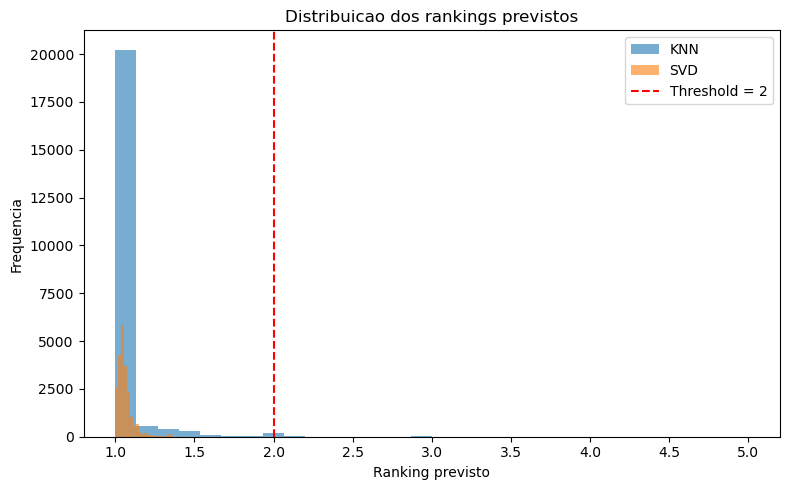

In [11]:
scores_knn = np.array([pred.est for pred in predictions_knn])
scores_svd = np.array([pred.est for pred in predictions_svd])

plt.figure(figsize=(8, 5))
plt.hist(scores_knn, bins=30, alpha=0.6, label="KNN")
plt.hist(scores_svd, bins=30, alpha=0.6, label="SVD")
plt.axvline(threshold_relevancia, color="red", linestyle="--", label=f"Threshold = {threshold_relevancia}")
plt.title("Distribuicao dos rankings previstos")
plt.xlabel("Ranking previsto")
plt.ylabel("Frequencia")
plt.legend()
plt.tight_layout()
plt.show()

### 7.2. Matriz de confusão

A matriz de confusão ajuda a interpretar precisão, recall e F1-score. Ela mostra quantas interações foram classificadas como negativas ou positivas em relação ao limiar definido.

No caso do SVD, a matriz tende a concentrar as predições na classe "não relevante", explicando por que o modelo pode ter boa acurácia e bom RMSE/MAE, mas F1-score zerado na classificação binária.

In [12]:
def montar_matriz_confusao(predictions, threshold=2):
    y_true = [1 if pred.r_ui >= threshold else 0 for pred in predictions]
    y_pred = [1 if pred.est >= threshold else 0 for pred in predictions]

    matriz = confusion_matrix(y_true, y_pred, labels=[0, 1])

    return pd.DataFrame(
        matriz,
        index=["Real nao relevante", "Real relevante"],
        columns=["Previsto nao relevante", "Previsto relevante"]
    )


matriz_confusao_knn = montar_matriz_confusao(predictions_knn, threshold_relevancia)
matriz_confusao_svd = montar_matriz_confusao(predictions_svd, threshold_relevancia)

matrizes_confusao = pd.concat(
    {
        "KNNWithMeans item-based": matriz_confusao_knn,
        "SVD/Funk SVD": matriz_confusao_svd
    },
    names=["Modelo", "Classe real"]
)

matrizes_confusao

Previsto nao relevante  \
Modelo                  Classe real                                  
KNNWithMeans item-based Real nao relevante                   20541   
                        Real relevante                        1279   
SVD/Funk SVD            Real nao relevante                   20676   
                        Real relevante                        1308   

                                            Previsto relevante  
Modelo                  Classe real                             
KNNWithMeans item-based Real nao relevante                 135  
                        Real relevante                      29  
SVD/Funk SVD            Real nao relevante                   0  
                        Real relevante                       0

### 7.3. Interpretação das métricas de classificação

A acurácia deve ser interpretada com cuidado, pois a base é desbalanceada e possui muitas interações não relevantes pelo limiar `ranking >= 2`. Assim, um modelo que prevê quase tudo como não relevante pode obter acurácia alta.

Para o SVD, precisão, recall e F1-score podem ficar zerados porque o modelo otimiza o erro numérico e gera predições conservadoras, concentradas abaixo do limiar de relevância. Isso não invalida o modelo para regressão, mas mostra que um threshold fixo não captura toda a qualidade de ranqueamento do recomendador.

### 7.4. Métricas Top-K

Como o objetivo final é recomendar uma lista de espetáculos, também foram calculadas métricas Top-K. Nesse caso, para cada usuário do conjunto de teste, o modelo ordena os itens previstos e avaliamos quantos itens realmente relevantes aparecem nas primeiras posições.

Neste notebook, a comparação agregada usa `k = 1`, pois o conjunto de teste tem poucos itens por usuário. Assim, a métrica avalia se a primeira recomendação ranqueada pelo modelo é realmente relevante, evitando empates artificiais de listas Top-10 muito grandes para o holdout disponível.

In [13]:
def avaliar_top_k(predictions, k=10, threshold=2):
    usuarios = defaultdict(list)

    for pred in predictions:
        usuarios[pred.uid].append({
            "item_id": pred.iid,
            "ranking_real": pred.r_ui,
            "ranking_previsto": pred.est,
            "relevante": pred.r_ui >= threshold
        })

    precisions = []
    recalls = []

    for itens in usuarios.values():
        total_relevantes = sum(item["relevante"] for item in itens)
        if total_relevantes == 0:
            continue

        top_k = sorted(itens, key=lambda item: item["ranking_previsto"], reverse=True)[:k]
        recomendados_relevantes = sum(item["relevante"] for item in top_k)

        precisions.append(recomendados_relevantes / k)
        recalls.append(recomendados_relevantes / total_relevantes)

    precision_at_k = np.mean(precisions) if precisions else 0
    recall_at_k = np.mean(recalls) if recalls else 0
    f1_at_k = (
        2 * precision_at_k * recall_at_k / (precision_at_k + recall_at_k)
        if (precision_at_k + recall_at_k) > 0
        else 0
    )

    return {
        f"Precision@{k}": precision_at_k,
        f"Recall@{k}": recall_at_k,
        f"F1@{k}": f1_at_k,
        "Usuarios avaliados": len(precisions)
    }


k_top = 1
metricas_top_k_knn = avaliar_top_k(predictions_knn, k=k_top, threshold=threshold_relevancia)
metricas_top_k_svd = avaliar_top_k(predictions_svd, k=k_top, threshold=threshold_relevancia)

comparacao_top_k = pd.DataFrame([
    {"Modelo": "KNNWithMeans item-based", **metricas_top_k_knn},
    {"Modelo": "SVD/Funk SVD", **metricas_top_k_svd}
])

comparacao_top_k

,Modelo,Precision@1,Recall@1,F1@1,Usuarios avaliados
0,KNNWithMeans item-based,0.884646,0.869398,0.876956,1257
1,SVD/Funk SVD,0.881464,0.866083,0.873706,1257


## 8. Visualizações comparativas

Para facilitar a análise dos resultados, foram gerados gráficos comparando os modelos nas métricas de regressão, classificação e Top-K.

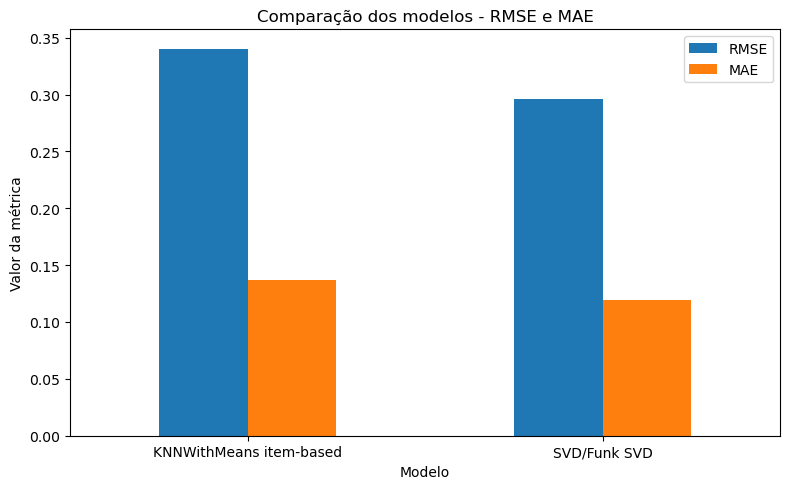

In [14]:
comparacao_regressao_plot = comparacao_regressao.set_index("Modelo")

comparacao_regressao_plot[["RMSE", "MAE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Comparação dos modelos - RMSE e MAE")
plt.ylabel("Valor da métrica")
plt.xlabel("Modelo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

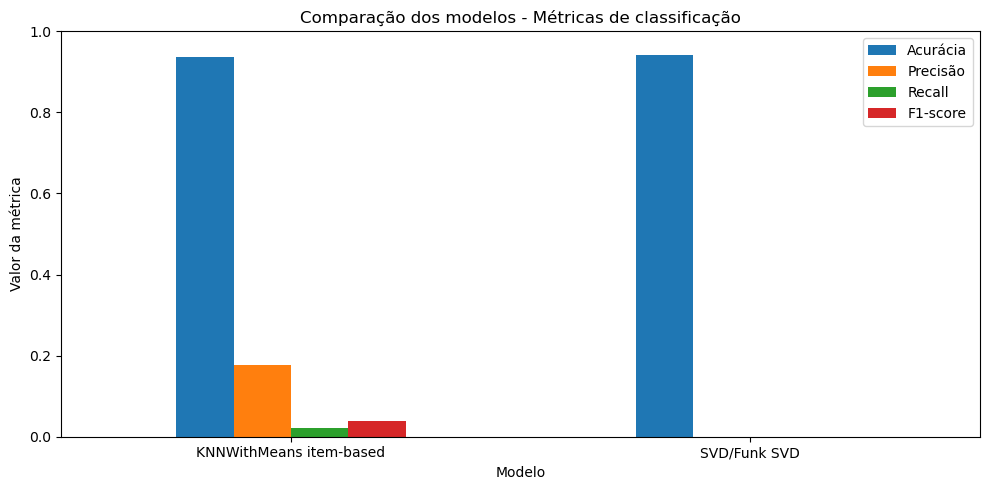

In [15]:
comparacao_classificacao_plot = comparacao_classificacao.set_index("Modelo")

comparacao_classificacao_plot[
    ["Acurácia", "Precisão", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparação dos modelos - Métricas de classificação")
plt.ylabel("Valor da métrica")
plt.xlabel("Modelo")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

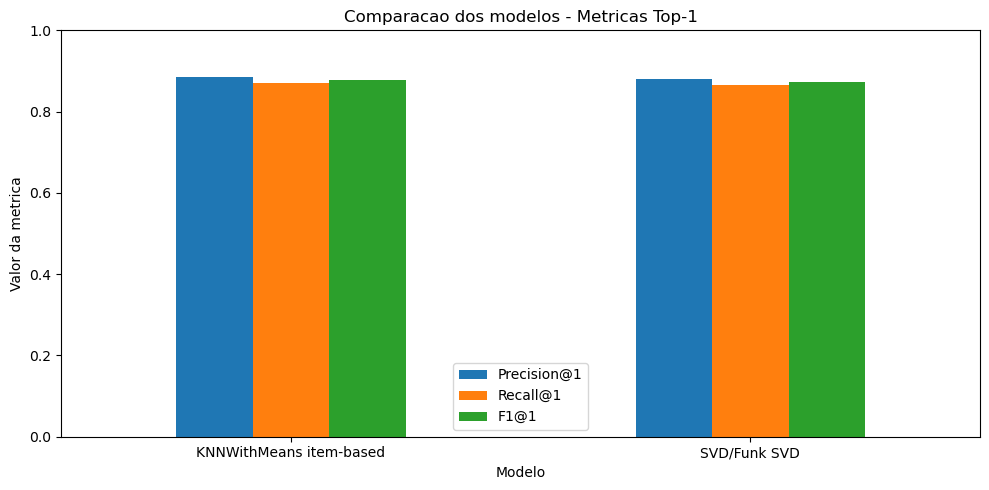

In [16]:
comparacao_top_k_plot = comparacao_top_k.set_index("Modelo")

comparacao_top_k_plot[
    [f"Precision@{k_top}", f"Recall@{k_top}", f"F1@{k_top}"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title(f"Comparacao dos modelos - Metricas Top-{k_top}")
plt.ylabel("Valor da metrica")
plt.xlabel("Modelo")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

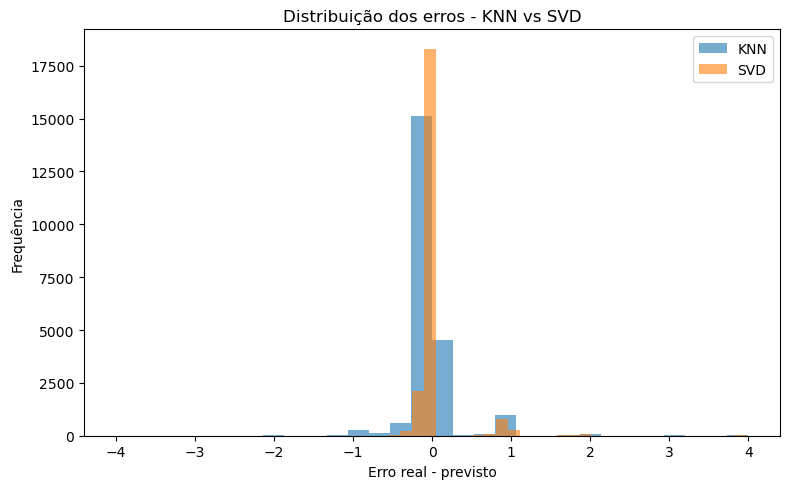

In [17]:
erros_knn = np.array([pred.r_ui - pred.est for pred in predictions_knn])
erros_svd = np.array([pred.r_ui - pred.est for pred in predictions_svd])

plt.figure(figsize=(8, 5))
plt.hist(erros_knn, bins=30, alpha=0.6, label="KNN")
plt.hist(erros_svd, bins=30, alpha=0.6, label="SVD")
plt.title("Distribuição dos erros - KNN vs SVD")
plt.xlabel("Erro real - previsto")
plt.ylabel("Frequência")
plt.legend()
plt.tight_layout()
plt.show()

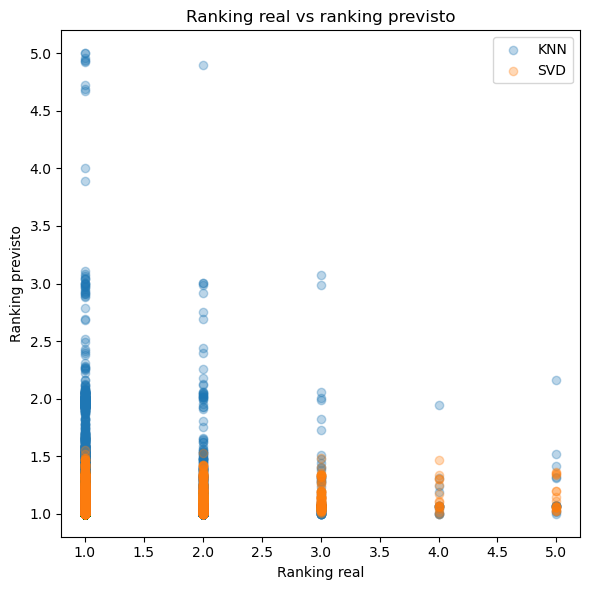

In [18]:
y_true_knn = np.array([pred.r_ui for pred in predictions_knn])
y_pred_knn = np.array([pred.est for pred in predictions_knn])

y_true_svd = np.array([pred.r_ui for pred in predictions_svd])
y_pred_svd = np.array([pred.est for pred in predictions_svd])

plt.figure(figsize=(6, 6))
plt.scatter(y_true_knn, y_pred_knn, alpha=0.3, label="KNN")
plt.scatter(y_true_svd, y_pred_svd, alpha=0.3, label="SVD")
plt.title("Ranking real vs ranking previsto")
plt.xlabel("Ranking real")
plt.ylabel("Ranking previsto")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Inferência comparativa

Nesta etapa, os dois modelos geram recomendações para o mesmo usuário. Isso permite observar se KNN e SVD sugerem os mesmos espetáculos ou se capturam padrões diferentes de preferência.

In [19]:
def recomendar_top_n(modelo, df, user_id, n=10):
    itens_consumidos = set(df.loc[df["user_id"] == user_id, "item_id"])
    itens_candidatos = [item for item in df["item_id"].unique() if item not in itens_consumidos]

    recomendacoes = [
        {"item_id": item, "score_predito": modelo.predict(user_id, item).est}
        for item in itens_candidatos
    ]

    return (
        pd.DataFrame(recomendacoes)
        .sort_values("score_predito", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )


usuario_exemplo = (
    df.groupby("user_id")
    .size()
    .reset_index(name="n_interacoes")
    .query("n_interacoes >= 3")
    .sample(1, random_state=42)["user_id"]
    .iloc[0]
)

historico_usuario = (
    df.loc[df["user_id"] == usuario_exemplo, ["item_id", "ranking"]]
    .sort_values("ranking", ascending=False)
    .reset_index(drop=True)
)

print(f"Usuário usado na inferência: {usuario_exemplo}")
historico_usuario

Usuário usado na inferência: 39332


,item_id,ranking
0,AFONSO PADILHA - NINGUÉM SE IMPORTA,1
1,GIOVANA FAGUNDES EM ORGULHO DO PAPAI,1
2,RENATO ALBANI EM NOVO SHOW,1


In [20]:
recomendacoes_knn = recomendar_top_n(modelo_knn, df, usuario_exemplo, n=10)
recomendacoes_svd = recomendar_top_n(modelo_svd, df, usuario_exemplo, n=10)

comparacao_inferencia = pd.concat(
    [
        recomendacoes_knn.rename(columns={
            "item_id": "KNN_item_id",
            "score_predito": "KNN_score_predito"
        }),
        recomendacoes_svd.rename(columns={
            "item_id": "SVD_item_id",
            "score_predito": "SVD_score_predito"
        })
    ],
    axis=1
)

comparacao_inferencia

,KNN_item_id,KNN_score_predito,SVD_item_id,SVD_score_predito
0,PRÊMIO SIM A IGUALDADE RACIAL 2023,4.000000,VOZES NEGRAS – A FORÇA DO CANTO FEMININO,1.346540
1,"JOYCE CÂNDIDO EM “UMA SAUDADE IMENSA"" - TRIBUT...",2.000000,PRÊMIO SIM A IGUALDADE RACIAL 2023,1.285015
2,ESTHER SAMUEL - ÀS MINHAS CRIANÇAS,1.538462,ESTHER SAMUEL - ÀS MINHAS CRIANÇAS,1.265414
3,MÁRCIO GOMES – “ETERNAS CANÇÕES” - BOLEROS,1.500000,ZAQUIM,1.200243
4,VOZES NEGRAS – A FORÇA DO CANTO FEMININO,1.353380,"EVOÉ, O MUSICAL",1.187439
5,PODER PRA NOSSA GENTE - PRETINHO DA SERRINHA E...,1.333333,ALEX ALBINO NO SOMAMOS FESTIVAL,1.184273
6,FESTIVAL DA CONSCIÊNCIA NEGRA - MÛ MBANA,1.250000,PAULA SANTORO - LANÇAMENTO DO ÁLBUM SUMAÚMA,1.183386
7,CEIÇA MORENO - MEU LUAR PARTICIPAÇÃO: CHICO C...,1.250000,SOMAMOS FESTIVAL - TUIM + PIETÁ + TROPICALS,1.170838
8,SOMAMOS FESTIVAL - BERADEROS,1.250000,MARIANA VOLKER NO SOMAMOS FESTIVAL,1.168119
9,"""MÚSICA, LETRA E DANÇA"" BABI XAVIER, CAROL FAZ...",1.250000,"""MÚSICA, LETRA E DANÇA"" BABI XAVIER, CAROL FAZ...",1.163335


## 10. Análise crítica dos resultados

A comparação entre KNN e SVD deve ser interpretada considerando as características da base da Aventura e o objetivo de uso do recomendador.

A base utilizada deriva da entrega da Sprint 1, que tinha natureza transacional: registros de compra/interação, e não notas explícitas dadas pelos usuários. Na Sprint 2, essas interações foram transformadas no campo `ranking`, usado como aproximação de interesse. Essa decisão tornou possível aplicar filtragem colaborativa, mas também trouxe impactos importantes: esparsidade alta, concentração de rankings baixos e dificuldade de separar preferência real de simples ocorrência transacional.

Nas métricas de regressão, o SVD/Funk SVD apresentou melhor desempenho, com menor RMSE e menor MAE. Isso indica maior capacidade de prever o valor numérico do ranking no conjunto de teste. Esse comportamento é coerente com a proposta do SVD, que aprende fatores latentes e vieses globais de usuários e itens.

Nas métricas de classificação, o resultado precisa ser lido com cautela. O SVD pode apresentar precisão, recall e F1-score iguais a zero porque suas predições ficam abaixo do limiar `ranking >= 2`, mesmo quando o erro médio é baixo. Isso mostra uma tensão entre avaliar o modelo como regressor e avaliá-lo como classificador binário em uma base desbalanceada.

O KNN item-based, por sua vez, é mais interpretável: recomenda espetáculos semelhantes aos que o usuário já consumiu. Ele tende a ser uma boa referência para explicar recomendações ao parceiro, ainda que tenha apresentado maior erro em RMSE e MAE.

Assim, a comparação final indica que o **SVD/Funk SVD é superior para previsão numérica de ranking**, enquanto o **KNN permanece competitivo e mais explicável para listas de recomendação baseadas em similaridade entre espetáculos**. A escolha do modelo final deve considerar o objetivo principal da aplicação: minimizar erro de predição, maximizar qualidade da lista ranqueada ou favorecer interpretabilidade.

## 11. Seleção do Modelo Final

### Justificativa da Escolha

Após a comparação sistemática nas seções anteriores, o **SVD/Funk SVD** foi selecionado como modelo final. A escolha se apoia em três critérios:

**1. Menor erro de predição**
O SVD apresentou RMSE de 0.2958 e MAE de 0.1190, contra RMSE de 0.3402 e MAE de 0.1366 do KNN — redução de ~13% em ambas as métricas. Isso indica que o SVD prevê com maior precisão o ranking esperado de um usuário para um espetáculo.

**2. Qualidade de lista Top-K equivalente**
Nas métricas Top-1, os modelos foram praticamente idênticos: Precision@1 de 0.8815 (SVD) vs 0.8846 (KNN), Recall@1 de 0.8661 vs 0.8694. O SVD mantém qualidade de lista comparável enquanto reduz o erro numérico.

**3. Generalização por fatores latentes**
O SVD aprende fatores latentes e vieses globais de usuários e itens, o que permite gerar recomendações mesmo para usuários com poucas interações. O KNN depende de vizinhos observados e degrada em cenários de cold-start.

O modelo selecionado para produção foi treinado sobre o dataset completo (100% das interações) com os hiperparâmetros encontrados pelo `GridSearchCV` no notebook `03_svd.ipynb`:

| Hiperparâmetro | Valor |
|---|---|
| `n_factors` | 10 |
| `lr_all` | 0.001 |
| `reg_all` | 0.2 |
| `n_epochs` | 50 |

In [21]:
resumo_selecao = pd.DataFrame({
    "Métrica": ["RMSE ↓", "MAE ↓", "Precision@1 ↑", "Recall@1 ↑", "F1@1 ↑"],
    "KNNWithMeans": [
        round(rmse_knn, 4), round(mae_knn, 4),
        round(metricas_top_k_knn["Precision@1"], 4),
        round(metricas_top_k_knn["Recall@1"], 4),
        round(metricas_top_k_knn["F1@1"], 4),
    ],
    "SVD/Funk SVD": [
        round(rmse_svd, 4), round(mae_svd, 4),
        round(metricas_top_k_svd["Precision@1"], 4),
        round(metricas_top_k_svd["Recall@1"], 4),
        round(metricas_top_k_svd["F1@1"], 4),
    ],
})

resumo_selecao["Vencedor"] = resumo_selecao.apply(
    lambda row: "SVD ✓" if (
        (row.name < 2 and row["SVD/Funk SVD"] < row["KNNWithMeans"]) or
        (row.name >= 2 and row["SVD/Funk SVD"] >= row["KNNWithMeans"])
    ) else "KNN ✓",
    axis=1
)

print("Modelo selecionado para produção: SVD/Funk SVD")
resumo_selecao

Modelo selecionado para produção: SVD/Funk SVD


,Métrica,KNNWithMeans,SVD/Funk SVD,Vencedor
0,RMSE ↓,0.3402,0.2958,SVD ✓
1,MAE ↓,0.1366,0.1190,SVD ✓
2,Precision@1 ↑,0.8846,0.8815,KNN ✓
3,Recall@1 ↑,0.8694,0.8661,KNN ✓
4,F1@1 ↑,0.8770,0.8737,KNN ✓


## 12. Exportação do Modelo Final

O modelo SVD foi treinado sobre o **dataset completo** (sem divisão treino/teste) para maximizar o aprendizado antes do uso em produção. Os hiperparâmetros são os mesmos selecionados pelo `GridSearchCV` no notebook `03_svd.ipynb`.

O arquivo exportado é `src/models/svd_model.joblib` e é carregado diretamente pelo módulo `src/models/inference.py` na inicialização.

In [22]:
import joblib

svd_params_final = {
    "n_factors": 10,
    "lr_all": 0.001,
    "reg_all": 0.2,
    "n_epochs": 50,
    "random_state": 42,
    "verbose": False,
}

reader_full = Reader(rating_scale=(1, 5))
data_full = Dataset.load_from_df(df[["user_id", "item_id", "ranking"]], reader_full)
trainset_full = data_full.build_full_trainset()

modelo_final = SVD(**svd_params_final)
modelo_final.fit(trainset_full)

possiveis_destinos = [
    Path("../models/svd_model.joblib"),
    Path("src/models/svd_model.joblib"),
]
destino = next((p for p in possiveis_destinos if p.parent.exists()), possiveis_destinos[0])

joblib.dump(modelo_final, destino)
print(f"Modelo exportado para: {destino.resolve()}")
print(f"n_users treinados: {trainset_full.n_users}")
print(f"n_items treinados: {trainset_full.n_items}")
print(f"n_ratings treinados: {trainset_full.n_ratings}")

Modelo exportado para: C:\Users\cadus\CADU_FILES\Inteli\Projeto 6 - Aventura\g02\src\models\svd_model.joblib
n_users treinados: 68499
n_items treinados: 449
n_ratings treinados: 109916


## 13. Função de Inferência Final

A inferência em produção é realizada pelo módulo `src/models/inference.py`, que carrega o modelo exportado e expõe uma função pública `recomendar`.

#### Estrutura do módulo

| Componente | Descrição |
|---|---|
| `_modelo` | SVD carregado de `svd_model.joblib` na inicialização do módulo |
| `_df` | Dataset CSV carregado para consulta de histórico e cold-start |
| `_todos_itens` | Conjunto de todos os `item_id` únicos |
| `_COLD_START_ITEMS` | Lista pré-computada de itens ordenados por popularidade |
| `recomendar(user_id, n)` | Função pública que retorna top-n recomendações |

#### Assinatura da função

```python
recomendar(user_id: int, n: int = 10) -> list[dict]
```

**Parâmetros:**
- `user_id`: identificador inteiro do usuário (campo `user_id` do dataset)
- `n`: número de recomendações a retornar (padrão 10)

**Retorno:** lista de dicts `{"espetaculo": str, "score": float | None}`, ordenada por score decrescente.

#### Fluxo de execução

1. Valida tipos e valores de `user_id` e `n` (lança `TypeError` ou `ValueError` em caso de erro).
2. Consulta os itens já consumidos pelo usuário no dataset.
3. **Cold-start** — se o usuário não existir no modelo ou não tiver histórico, retorna os top-n itens mais populares com `score=None`.
4. **Predição vetorizada** — usa os atributos internos do SVD (`pu`, `qi`, `bu`, `bi`) para calcular os scores de todos os itens com uma única multiplicação matricial BLAS, evitando 447 chamadas individuais ao Cython.
5. Filtra os itens já consumidos e retorna os top-n com maior score.

In [23]:
import sys
sys.path.insert(0, str(Path("../..").resolve()))

from src.models.inference import recomendar

exemplo = recomendar(usuario_exemplo, n=5)
print(f"Top-5 recomendações para usuário {usuario_exemplo}:")
for i, rec in enumerate(exemplo, 1):
    score_str = f"{rec['score']:.4f}" if rec["score"] is not None else "N/A (popularidade)"
    print(f"  {i}. {rec['espetaculo']} — score: {score_str}")

Top-5 recomendações para usuário 39332:
  1. VOZES NEGRAS – A FORÇA DO CANTO FEMININO — score: 1.3101
  2. ESTHER SAMUEL - ÀS MINHAS CRIANÇAS — score: 1.2485
  3. ZAQUIM — score: 1.1944
  4. CONTANDO UM CONTO - CIA LIVRE DE DANÇA DA ROCINHA — score: 1.1924
  5. SOMAMOS FESTIVAL - TUIM + PIETÁ + TROPICALS — score: 1.1729


## 14. Conclusões

### Síntese dos resultados

Este notebook comparou dois algoritmos de filtragem colaborativa — KNN item-based e SVD/Funk SVD — sobre o mesmo dataset, a mesma divisão treino/teste e as mesmas métricas de avaliação.

**Métricas de regressão:** o SVD apresentou desempenho superior com RMSE de 0.2958 (vs 0.3402 do KNN) e MAE de 0.1190 (vs 0.1366), redução de ~13% em ambas as métricas. O SVD aprende fatores latentes que capturam padrões de preferência não capturados por vizinhança.

**Métricas de classificação:** ambos os modelos apresentaram limitações ao transformar o problema em classificação binária com limiar `ranking >= 2`. A base é altamente desbalanceada (94% das interações com `ranking = 1`), o que faz o SVD otimizar o erro numérico sem ultrapassar o limiar — resultando em F1-score zero. Isso não invalida o modelo para a tarefa de regressão e ranking, mas indica que o limiar fixo é uma métrica inadequada isoladamente para feedback implícito.

**Métricas Top-K:** ambos os modelos tiveram desempenho muito próximo, com Precision@1 ~0.88 e Recall@1 ~0.87. Isso confirma que, na tarefa principal — ordenar espetáculos relevantes no topo da lista — o SVD é equivalente ao KNN.

**Modelo selecionado:** SVD/Funk SVD, exportado em `src/models/svd_model.joblib` e servido pela função `recomendar` em `src/models/inference.py`.

### Limitações identificadas

- O dataset tem alta esparsidade (99,6%), o que restringe o aprendizado de fatores latentes para usuários com poucas interações.
- O threshold de classificação `ranking >= 2` pode não capturar a qualidade do ordenamento completo; métricas como NDCG seriam mais adequadas para avaliação de ranking.